# Tenant Satisfaction Measures: Step 4, charts that tell the story

Tables are fine for me, but nobody else wants to read them, so in this notebook I turn the main results into four charts. Each one answers a single question:

1. **Does the way a survey is run matter?** Overall satisfaction by survey method
2. **What moves with satisfaction?** The two strongest operational links, across every housing association
3. **What matters most, all else equal?** The regression results from step 3
4. **How well does the model do?** Every landlord's actual score against its prediction

I tried to make each chart's title state the finding, so someone gets the point without having to study it. They're saved as PNG files for the README.

## 1. Load the data and rebuild the step 3 model

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

try:
    from google.colab import files
    uploaded = files.upload()
    path = list(uploaded.keys())[0]
except ImportError:
    path = "../data/2025_TSM_Full_Data_v1.1_FINAL.xlsx"

In [2]:
# Steps 2 and 3 squashed together: load, tidy, join, and fit the same regression.
missing_codes = ["[X]", "[Z]", "[E]", "[U]"]
lcra = pd.read_excel(path, sheet_name="TSM25_LCRA_Perception", header=10, na_values=missing_codes)
mi = pd.read_excel(path, sheet_name="TSM25_Management_Info", header=9, na_values=missing_codes)

tp_pattern = r"^Proportion of respondents who report that they are satisfied.*\((TP\d{2})\)\d*$"
rename_map = {c: m for c in lcra.columns
              if pd.notna(m := pd.Series([c]).str.extract(tp_pattern).iloc[0, 0])}
rename_map.update({
    "Landlord name": "landlord", "Landlord code": "code", "Landlord type": "type",
    "Landlord group size (homes owned, LCRA and LCHO combined)": "size_band",
    "Landlord predominant region": "region", "Predominant collection method": "method",
})
tp_cols = sorted(v for v in rename_map.values() if v.startswith("TP"))
perception = lcra.rename(columns=rename_map)[
    ["landlord", "code", "type", "size_band", "region", "method"] + tp_cols]

def find_col(df, must_contain, starts_with=None):
    hits = [c for c in df.columns if all(t in c for t in must_contain)
            and (starts_with is None or c.startswith(starts_with))]
    assert len(hits) == 1, f"Expected 1 match for {must_contain}, found {len(hits)}"
    return hits[0]

# Only the four measures the model uses this time.
mi_measures = {
    "non_decent_pc":            (["(RP01)"], "Proportion"),
    "repairs_on_time_pc":       (["(RP02 1)"], "Proportion"),
    "complaints_s1_on_time_pc": (["(CH02 1)"], "LCRA"),
    "complaints_s2_per_1000":   (["(CH01 2)"], "LCRA"),
}
management = pd.DataFrame({"code": mi["Landlord code"]})
for short, (texts, start) in mi_measures.items():
    management[short] = pd.to_numeric(mi[find_col(mi, texts, start)], errors="coerce")

df = perception.merge(management, on="code", how="inner", validate="one_to_one")
has = df[df["type"] == "PRP"].copy()

has["method_group"] = pd.Categorical(
    has["method"].where(has["method"].isin(["Telephone", "Internet", "Postal"]), "Other"),
    ["Telephone", "Internet", "Postal", "Other"])
has["size_band"] = pd.Categorical(has["size_band"], ["5,000-40,000", "<5,000", ">40,000"])
has["region"] = pd.Categorical(has["region"], ["South", "North", "Midlands", "London", "Mixed"])

operations = ["complaints_s2_per_1000", "non_decent_pc",
              "repairs_on_time_pc", "complaints_s1_on_time_pc"]
model_data = has.dropna(subset=["TP01"] + operations).copy()
full = smf.ols(f"TP01 ~ {' + '.join(operations)} + C(method_group) + C(size_band) + C(region)",
               data=model_data).fit(cov_type="HC3")
print(f"Model R-squared {full.rsquared:.2f} across {int(full.nobs)} housing associations")

Model R-squared 0.59 across 194 housing associations


## 2. A consistent chart style

I wanted every chart to look like it belongs to the same project, and to keep them quiet so the data is the only loud thing. My rules:

- **Grey for context** and **one blue for the thing that matters**, so your eye goes straight to it
- **Thin, light gridlines** that sit behind the data
- **Titles that say the finding**, with the detail and the source underneath
- Colours that still work for colour-blind readers

In [3]:
# My colour palette, saved as variables so every chart uses exactly the same shades.
SURFACE = "#ffffff"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e4e3df", "#c3c2b7"
HIGHLIGHT = "#2a78d6"   # the thing to look at
ACCENT = "#eb6834"      # used sparingly
CONTEXT = "#c3c2b7"     # background data
SOURCE = "Source: Regulator of Social Housing, Tenant Satisfaction Measures 2025 full data set (2024/25)"

# rcParams changes matplotlib's defaults, so I don't have to restyle every chart by hand.
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Inter", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.major.size": 0, "ytick.major.size": 0, "xtick.minor.size": 0,
    "axes.spines.top": False, "axes.spines.right": False,
})

# A helper that adds the title, subtitle and source in the same place on every chart.
def titles(fig, title, subtitle):
    """Finding as the title, detail as the subtitle, source at the bottom."""
    fig.text(0.02, 0.98, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.02, 0.925, subtitle, ha="left", va="top", fontsize=10, color=INK_2)
    fig.text(0.02, 0.015, SOURCE, ha="left", va="bottom", fontsize=8, color=MUTED)

# Make a folder for the charts (exist_ok=True means no error if it's already there).
os.makedirs("charts", exist_ok=True)

## Chart 1: Does the way a survey is run matter?

Step 1 showed a big difference in median satisfaction between survey methods, so I wanted to see the whole spread, not just the medians. Each grey dot is a landlord and the blue line is the median for that method. I've shown the four main methods (the other 23 landlords used SMS or had no main method).

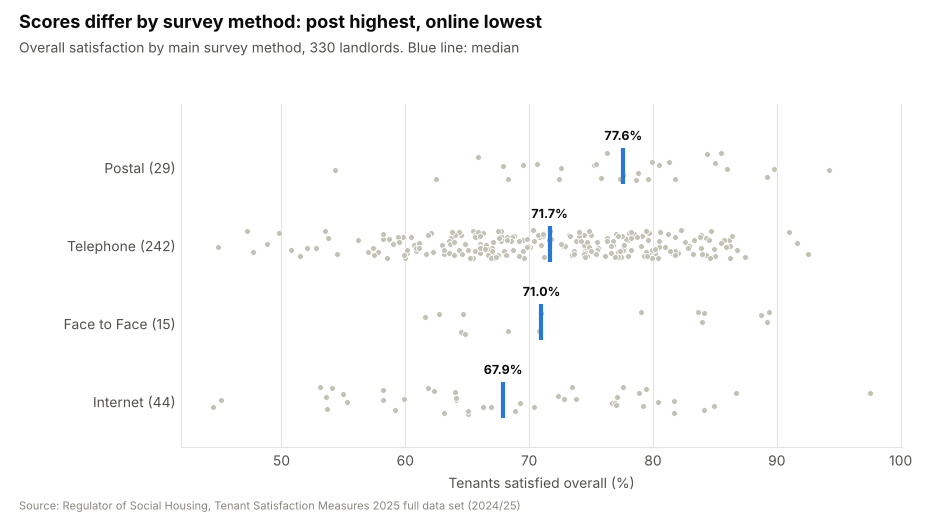

In [4]:
methods = ["Postal", "Telephone", "Face to Face", "Internet"]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
fig.subplots_adjust(left=0.19, right=0.95, top=0.80, bottom=0.14)

# A little random up-and-down "jitter" stops the dots sitting on top of each other.
rng = np.random.default_rng(1)
for yi, m in enumerate(methods[::-1]):   # reversed, so Postal ends up at the top
    # I use the full survey table here (all 353 landlords), so the medians match step 1.
    vals = perception.loc[perception["method"] == m, "TP01"].dropna()
    ax.scatter(vals, yi + rng.uniform(-0.18, 0.18, len(vals)), s=18, color=CONTEXT,
               edgecolors=SURFACE, linewidths=0.6, zorder=2)
    # The median as a tall blue tick, with its value just above.
    med = vals.median()
    ax.scatter(med, yi, marker="|", s=700, linewidths=3, color=HIGHLIGHT, zorder=3)
    ax.text(med, yi + 0.3, f"{med:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold", color=INK)

# Labels like "Postal (29)": the method and how many landlords used it.
ax.set_yticks(range(len(methods)), [f"{m} ({(perception['method'] == m).sum()})" for m in methods[::-1]])
ax.set_ylim(-0.6, len(methods) - 0.2)
ax.set_xlabel("Tenants satisfied overall (%)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

shown = perception["method"].isin(methods).sum()
titles(fig, "Scores differ by survey method: post highest, online lowest",
       f"Overall satisfaction by main survey method, {shown} landlords. Blue line: median")
fig.savefig("charts/1_survey_method.png", dpi=200)
plt.show()

## Chart 2: What moves with satisfaction?

These are the two strongest operational links from step 2, side by side. Each dot is a housing association and the line is the straight-line trend. I used **two separate panels with their own axes** rather than one chart with two y-axes, because I read that dual axes can make it look like the two scales are related when they're not.

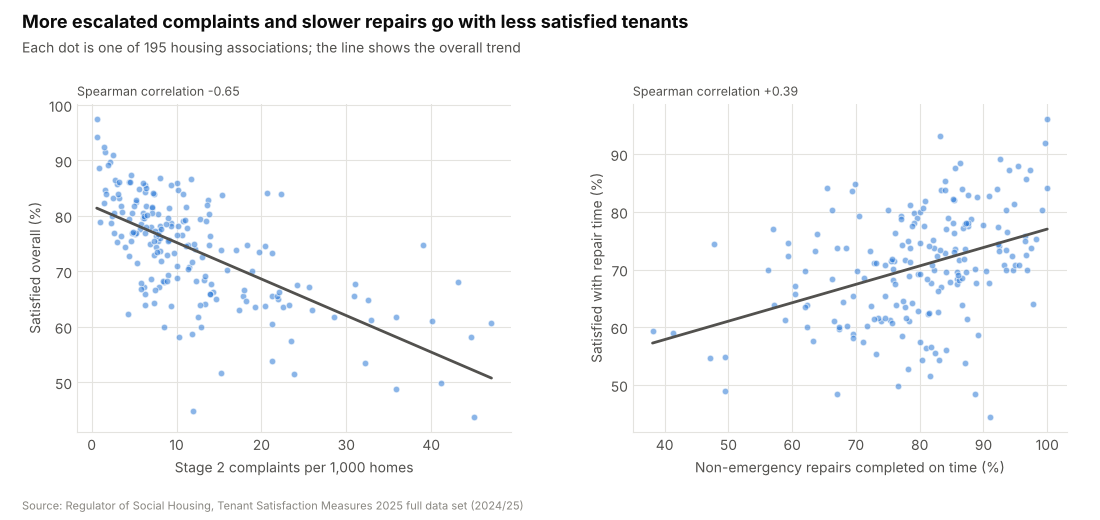

In [5]:
from scipy.stats import spearmanr

# Each panel: (x column, y column, x label, y label).
panels = [
    ("complaints_s2_per_1000", "TP01", "Stage 2 complaints per 1,000 homes", "Satisfied overall (%)"),
    ("repairs_on_time_pc", "TP03", "Non-emergency repairs completed on time (%)", "Satisfied with repair time (%)"),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
fig.subplots_adjust(left=0.07, right=0.97, top=0.80, bottom=0.17, wspace=0.28)

for ax, (x_col, y_col, x_label, y_label) in zip(axes, panels):
    # Every housing association as a dot.
    data = has.dropna(subset=[x_col, y_col])
    ax.scatter(data[x_col], data[y_col], s=22, color=HIGHLIGHT, alpha=0.55, edgecolors=SURFACE, linewidths=0.8)

    # np.polyfit(..., 1) fits a straight line and gives back its slope and intercept.
    slope, intercept = np.polyfit(data[x_col], data[y_col], 1)
    xs = np.linspace(data[x_col].min(), data[x_col].max(), 50)
    ax.plot(xs, intercept + slope * xs, color=INK_2, linewidth=2, solid_capstyle="round")

    rho = spearmanr(data[x_col], data[y_col]).statistic
    ax.set_title(f"Spearman correlation {rho:+.2f}", loc="left", fontsize=9, color=INK_2)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

titles(fig, "More escalated complaints and slower repairs go with less satisfied tenants",
       f"Each dot is one of {len(has)} housing associations; the line shows the overall trend")
fig.savefig("charts/2_drivers.png", dpi=200)
plt.show()

## Chart 3: What matters most, all else equal?

This shows the step 3 regression as a **coefficient plot**. Each dot is the expected change in overall satisfaction when a landlord moves from the 25th to the 75th percentile on that measure, with the others held the same. The whisker is the 95% confidence interval: if it crosses zero, I can't be sure which way the effect goes.

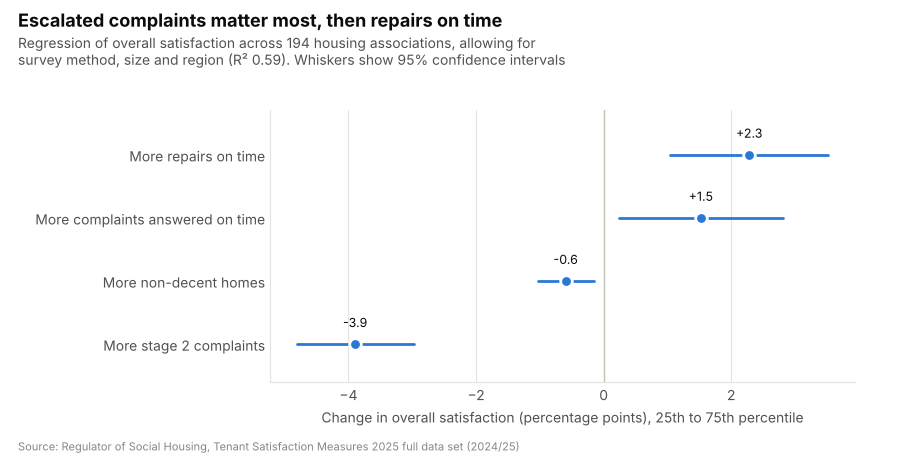

In [6]:
# Plain English labels for the four measures.
plain = {
    "complaints_s2_per_1000": "More stage 2 complaints",
    "non_decent_pc": "More non-decent homes",
    "repairs_on_time_pc": "More repairs on time",
    "complaints_s1_on_time_pc": "More complaints answered on time",
}
# Multiply each coefficient (and its confidence interval) by the gap between the 25th and 75th percentile.
iqr = model_data[operations].quantile(0.75) - model_data[operations].quantile(0.25)
ci = full.conf_int()
effects = pd.DataFrame({
    "effect": full.params[operations] * iqr,
    "low": ci.loc[operations, 0] * iqr,
    "high": ci.loc[operations, 1] * iqr,
}).sort_values("effect")
y = np.arange(len(effects))

fig, ax = plt.subplots(figsize=(9, 4.6))
fig.subplots_adjust(left=0.30, right=0.95, top=0.76, bottom=0.17)

# A line at zero, then the whiskers, the dots, and the value above each dot.
ax.axvline(0, color=BASELINE, linewidth=1)
ax.hlines(y, effects["low"], effects["high"], color=HIGHLIGHT, linewidth=2, capstyle="round")
ax.scatter(effects["effect"], y, s=70, color=HIGHLIGHT, edgecolors=SURFACE, linewidths=2, zorder=3)
for yi, (_, r) in zip(y, effects.iterrows()):
    ax.text(r["effect"], yi + 0.22, f"{r['effect']:+.1f}", ha="center", va="bottom", fontsize=9, color=INK)

ax.set_yticks(y, [plain[m] for m in effects.index])
ax.set_ylim(-0.6, len(effects) - 0.3)
ax.set_xlabel("Change in overall satisfaction (percentage points), 25th to 75th percentile")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

titles(fig, "Escalated complaints matter most, then repairs on time",
       f"Regression of overall satisfaction across {int(full.nobs)} housing associations, allowing for\n"
       f"survey method, size and region (R² {full.rsquared:.2f}). Whiskers show 95% confidence intervals")
fig.savefig("charts/3_model_effects.png", dpi=200)
plt.show()

## Chart 4: How well does the model do?

Every housing association's actual overall satisfaction against what the model predicts. If the model were perfect, every dot would sit on the diagonal line. The shaded band shows landlords within 5 points of their prediction.

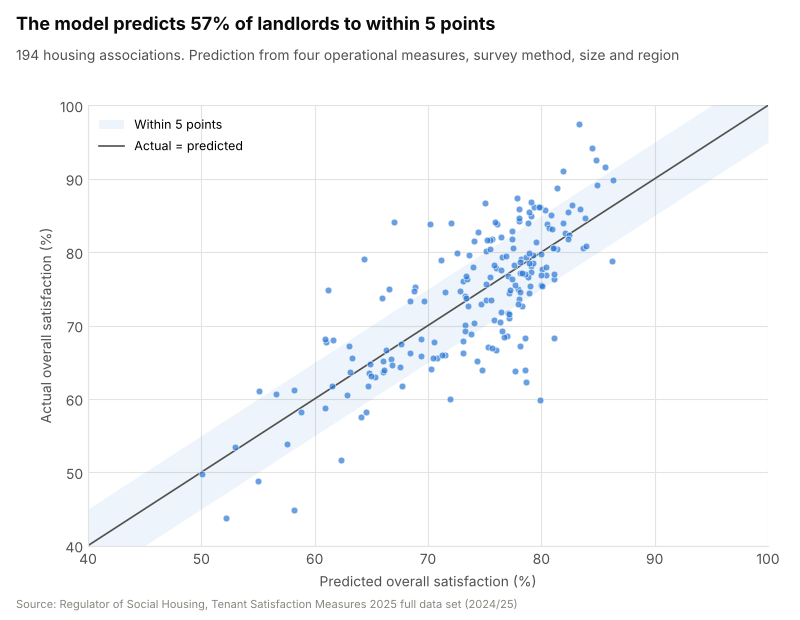

In [7]:
# Each landlord's prediction and its gap (residual), as in step 3.
model_data["predicted"] = full.predict(model_data)
model_data["residual"] = model_data["TP01"] - model_data["predicted"]
within_5 = (model_data["residual"].abs() <= 5).mean()

fig, ax = plt.subplots(figsize=(8, 6.2))
fig.subplots_adjust(left=0.11, right=0.96, top=0.83, bottom=0.12)

# The band and the diagonal first, so the dots sit on top.
xs = np.array([40, 100])
ax.fill_between(xs, xs - 5, xs + 5, color=HIGHLIGHT, alpha=0.08, linewidth=0, label="Within 5 points")
ax.plot(xs, xs, color=INK_2, linewidth=1.2, label="Actual = predicted")
ax.scatter(model_data["predicted"], model_data["TP01"], s=24, color=HIGHLIGHT, alpha=0.7,
           edgecolors=SURFACE, linewidths=0.6, zorder=3)

ax.set_xlim(40, 100)
ax.set_ylim(40, 100)
ax.set_xlabel("Predicted overall satisfaction (%)")
ax.set_ylabel("Actual overall satisfaction (%)")
ax.legend(loc="upper left", frameon=False, fontsize=9)

titles(fig, f"The model predicts {within_5:.0%} of landlords to within 5 points",
       f"{int(full.nobs)} housing associations. Prediction from four operational measures, "
       "survey method, size and region")
fig.savefig("charts/4_actual_vs_predicted.png", dpi=200)
plt.show()

**Something I want to be careful about with chart 4:** a dot far from the line isn't a measure of anything in particular. It's just what's left after the model's four operational measures and context. It could be communication, whether tenants feel listened to, local factors, or how the survey was run. So the gaps are prompts for more questions rather than findings on their own, and that's what notebooks 5 onwards look into.

## 3. Download the charts

In [8]:
# Zip up the charts folder and download it in Colab. Outside Colab, "files" doesn't exist,
# which raises a NameError, so I just print where the charts are instead.
import shutil
shutil.make_archive("tsm_charts", "zip", "charts")
try:
    files.download("tsm_charts.zip")
except NameError:
    print("Charts saved in the charts folder")

Charts saved in the charts folder


## What I found in step 4

- **Chart 1:** how a survey is run makes a real difference. Landlords surveying mainly by post have a median overall satisfaction of 77.6%, against 67.9% online, which is why the models allow for survey method.
- **Chart 2:** more escalated complaints and slower repairs go with less satisfied tenants, across all housing associations.
- **Chart 3:** escalated complaints matter most, then repairs on time.
- **Chart 4:** the model predicts 57% of landlords to within 5 points. The rest are where something beyond the operational measures is going on.

**Next:** step 5 tests whether area deprivation explains the gaps the model can't.